In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB



from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier

In [ ]:
df=pd.read_csv('dataset/diabetes_patients_10000_full.csv')
df.head(30)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   object 
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 781.4+ KB


In [4]:
df.describe()

,Patient_ID,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,10000.00000,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,5000.50000,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,2886.89568,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,1.00000,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,2500.75000,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,5000.50000,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,7500.25000,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,10000.00000,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [5]:
df.shape

(10000, 10)

In [6]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Blood_Sugar_Level', 'Creatinine', 'BMI',
       'Urea', 'Cholesterol', 'HbA1c', 'Class'],
      dtype='object')

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

Patient_ID            0
Age                  14
Gender               40
Blood_Sugar_Level    53
Creatinine           56
BMI                  51
Urea                 51
Cholesterol          32
HbA1c                 0
Class                 0
dtype: int64

In [9]:
df = df.dropna(subset=['Gender'])

In [10]:

impute = SimpleImputer(strategy='mean')

df[['Blood_Sugar_Level','Cholesterol']] = impute.fit_transform(
    df[['Blood_Sugar_Level','Cholesterol']]
)

In [11]:

impute = SimpleImputer(strategy='mean')

df[['Creatinine']] = impute.fit_transform(
    df[['Creatinine']]
)

In [12]:

impute = SimpleImputer(strategy='mean')

df[['Age','BMI','Urea']] = impute.fit_transform(
    df[['Age','BMI','Urea']]
)

In [13]:
df.isnull().sum()

Patient_ID           0
Age                  0
Gender               0
Blood_Sugar_Level    0
Creatinine           0
BMI                  0
Urea                 0
Cholesterol          0
HbA1c                0
Class                0
dtype: int64

In [14]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
gender_encoder = LabelEncoder()
df['Gender'] = gender_encoder.fit_transform(df['Gender'])

In [15]:
if 'Patient_ID' in df.columns:
    df = df.drop(columns=['Patient_ID'])

In [16]:
df = df.fillna(df.mean(numeric_only=True))

In [17]:
df = df.fillna(df.select_dtypes(include=['number']).mean())

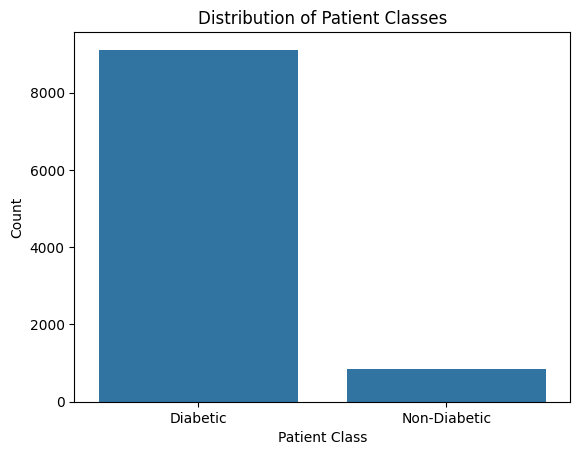

In [18]:
sns.countplot(data=df, x='Class')
plt.title('Distribution of Patient Classes')
plt.xlabel('Patient Class')
plt.ylabel('Count')
plt.show()

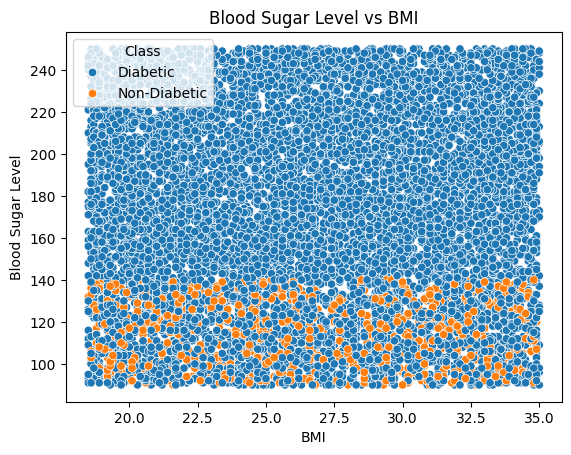

In [19]:
sns.scatterplot(data=df,x='BMI',y='Blood_Sugar_Level',hue='Class')
plt.title('Blood Sugar Level vs BMI')
plt.xlabel('BMI')
plt.ylabel('Blood Sugar Level')
plt.show()

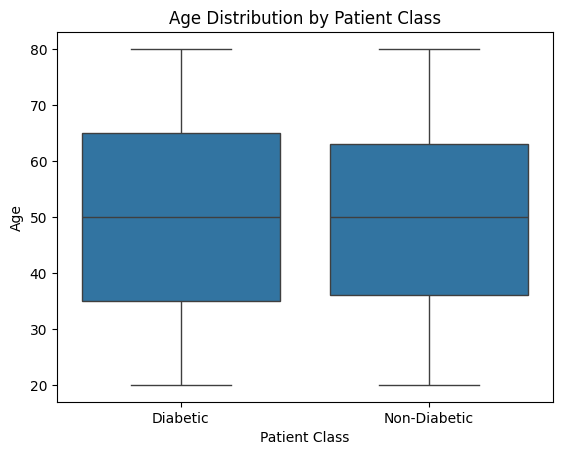

In [20]:
sns.boxplot(data=df, x='Class', y='Age')
plt.title('Age Distribution by Patient Class')
plt.xlabel('Patient Class')
plt.ylabel('Age')
plt.show()

In [21]:

X = df.drop(columns=['Class'])
y = df['Class']







In [22]:
target_encoder = LabelEncoder()
df['Class'] = target_encoder.fit_transform(df['Class'])

In [23]:
X = df.drop(columns=['Class'])
y = df['Class']



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# scale after the split to avoid data leakage
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [26]:

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print( classification_report(y_test, y_pred_knn))

Accuracy: 0.9618473895582329
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1822
           1       0.84      0.68      0.75       170

    accuracy                           0.96      1992
   macro avg       0.91      0.84      0.87      1992
weighted avg       0.96      0.96      0.96      1992



In [27]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print( classification_report(y_test, y_pred_dt))

Accuracy: 0.9994979919678715
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1822
           1       0.99      1.00      1.00       170

    accuracy                           1.00      1992
   macro avg       1.00      1.00      1.00      1992
weighted avg       1.00      1.00      1.00      1992



In [28]:

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

print('Train Accuracy:', lr_model.score(X_train, y_train))
print('Test Accuracy:', lr_model.score(X_test, y_test))

Train Accuracy: 0.9727660642570282
Test Accuracy: 0.9693775100401606


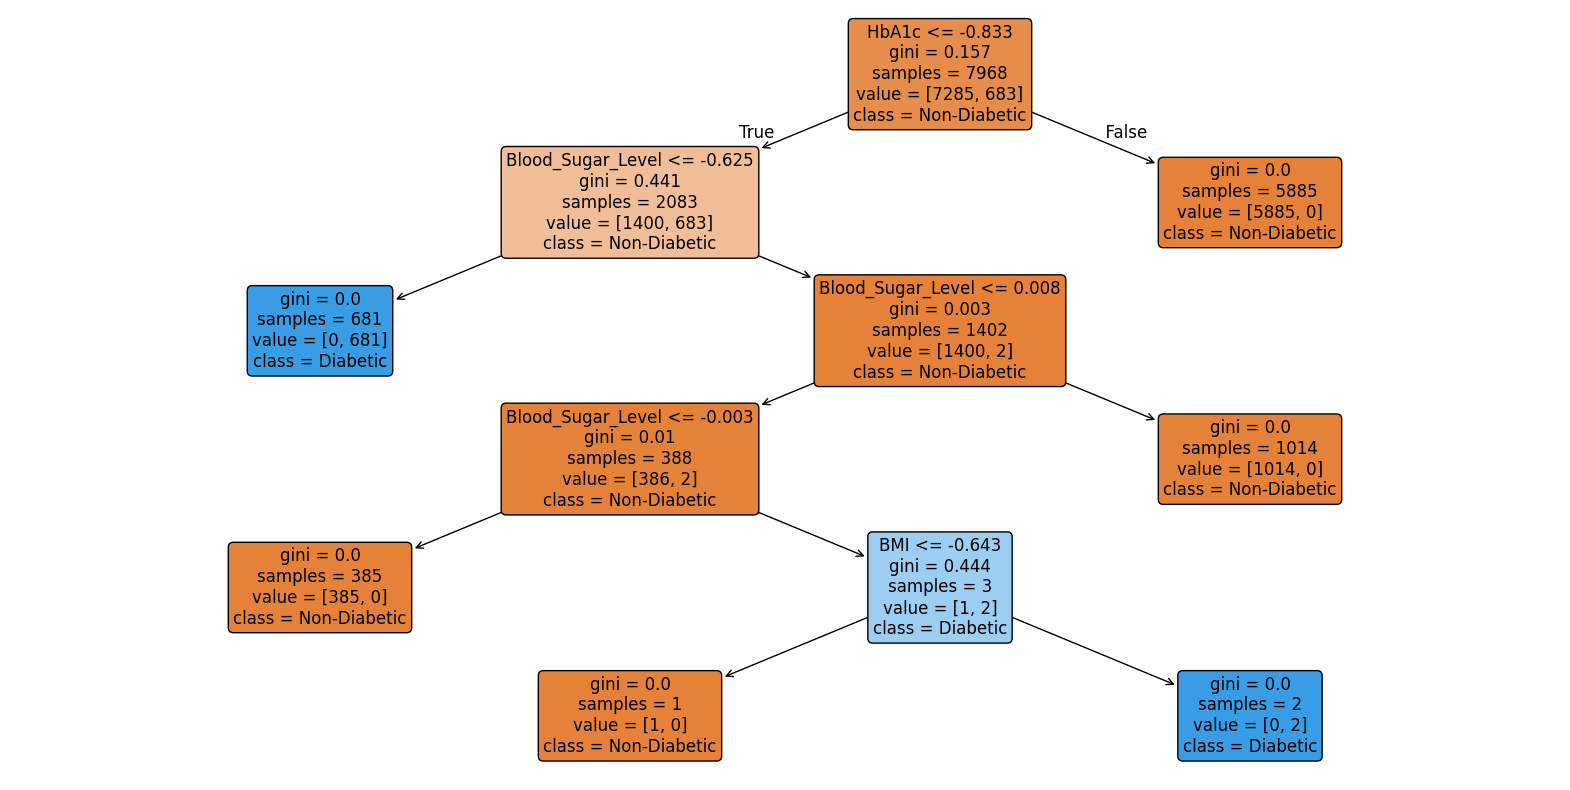

In [29]:
from sklearn.tree import plot_tree
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=X.columns.tolist(),
    class_names=['Non-Diabetic', 'Diabetic'],
    filled=True,
    rounded=True,
    fontsize=12,
)
plt.show()

In [30]:
dt_params = {
    'max_depth': [3, 5, 10, None],
    'criterion': ['gini', 'entropy'],
    'min_samples_split': [2, 5, 10],
}
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42), dt_params, cv=5, scoring='accuracy'
)
dt_grid.fit(X_train, y_train)

print('Decision Tree Best Params:', dt_grid.best_params_)
print('Decision Tree Best Score:', dt_grid.best_score_)

Decision Tree Best Params: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}
Decision Tree Best Score: 0.9997490589711419


In [31]:
X_train_scaled = X_train
X_test_scaled = X_test

In [32]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
    AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Lasso": LogisticRegression(penalty='l1', solver='liblinear'),
    "Ridge": RidgeClassifier(),
    "KNN": KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=1),
    "SVM": SVC(kernel='rbf', C=1),
    "Decision Tree": DecisionTreeClassifier(criterion='gini', max_depth=10),
    "Random Forest": RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=100, random_state=42),
    "Bagging": BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=10), n_estimators=15, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
}

In [33]:
clf_results = []
clf_preds = {}

for name, model in clf_models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    clf_preds[name] = y_pred

    clf_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0)
    })

clf_results_df = pd.DataFrame(clf_results).sort_values(by='F1 Score', ascending=False)
clf_results_df.reset_index(drop=True, inplace=True)
clf_results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,1.000000,1.000000,1.000000,1.000000
1,CatBoost,1.000000,1.000000,1.000000,1.000000
2,LightGBM,1.000000,1.000000,1.000000,1.000000
3,HistGradientBoosting,1.000000,1.000000,1.000000,1.000000
4,XGBoost,1.000000,1.000000,1.000000,1.000000
5,AdaBoost,1.000000,1.000000,1.000000,1.000000
6,Decision Tree,0.999498,0.994152,1.000000,0.997067
7,GradientBoosting,0.999498,0.994152,1.000000,0.997067
8,Bagging,0.999498,0.994152,1.000000,0.997067
9,ExtraTrees,0.988956,1.000000,0.870588,0.930818


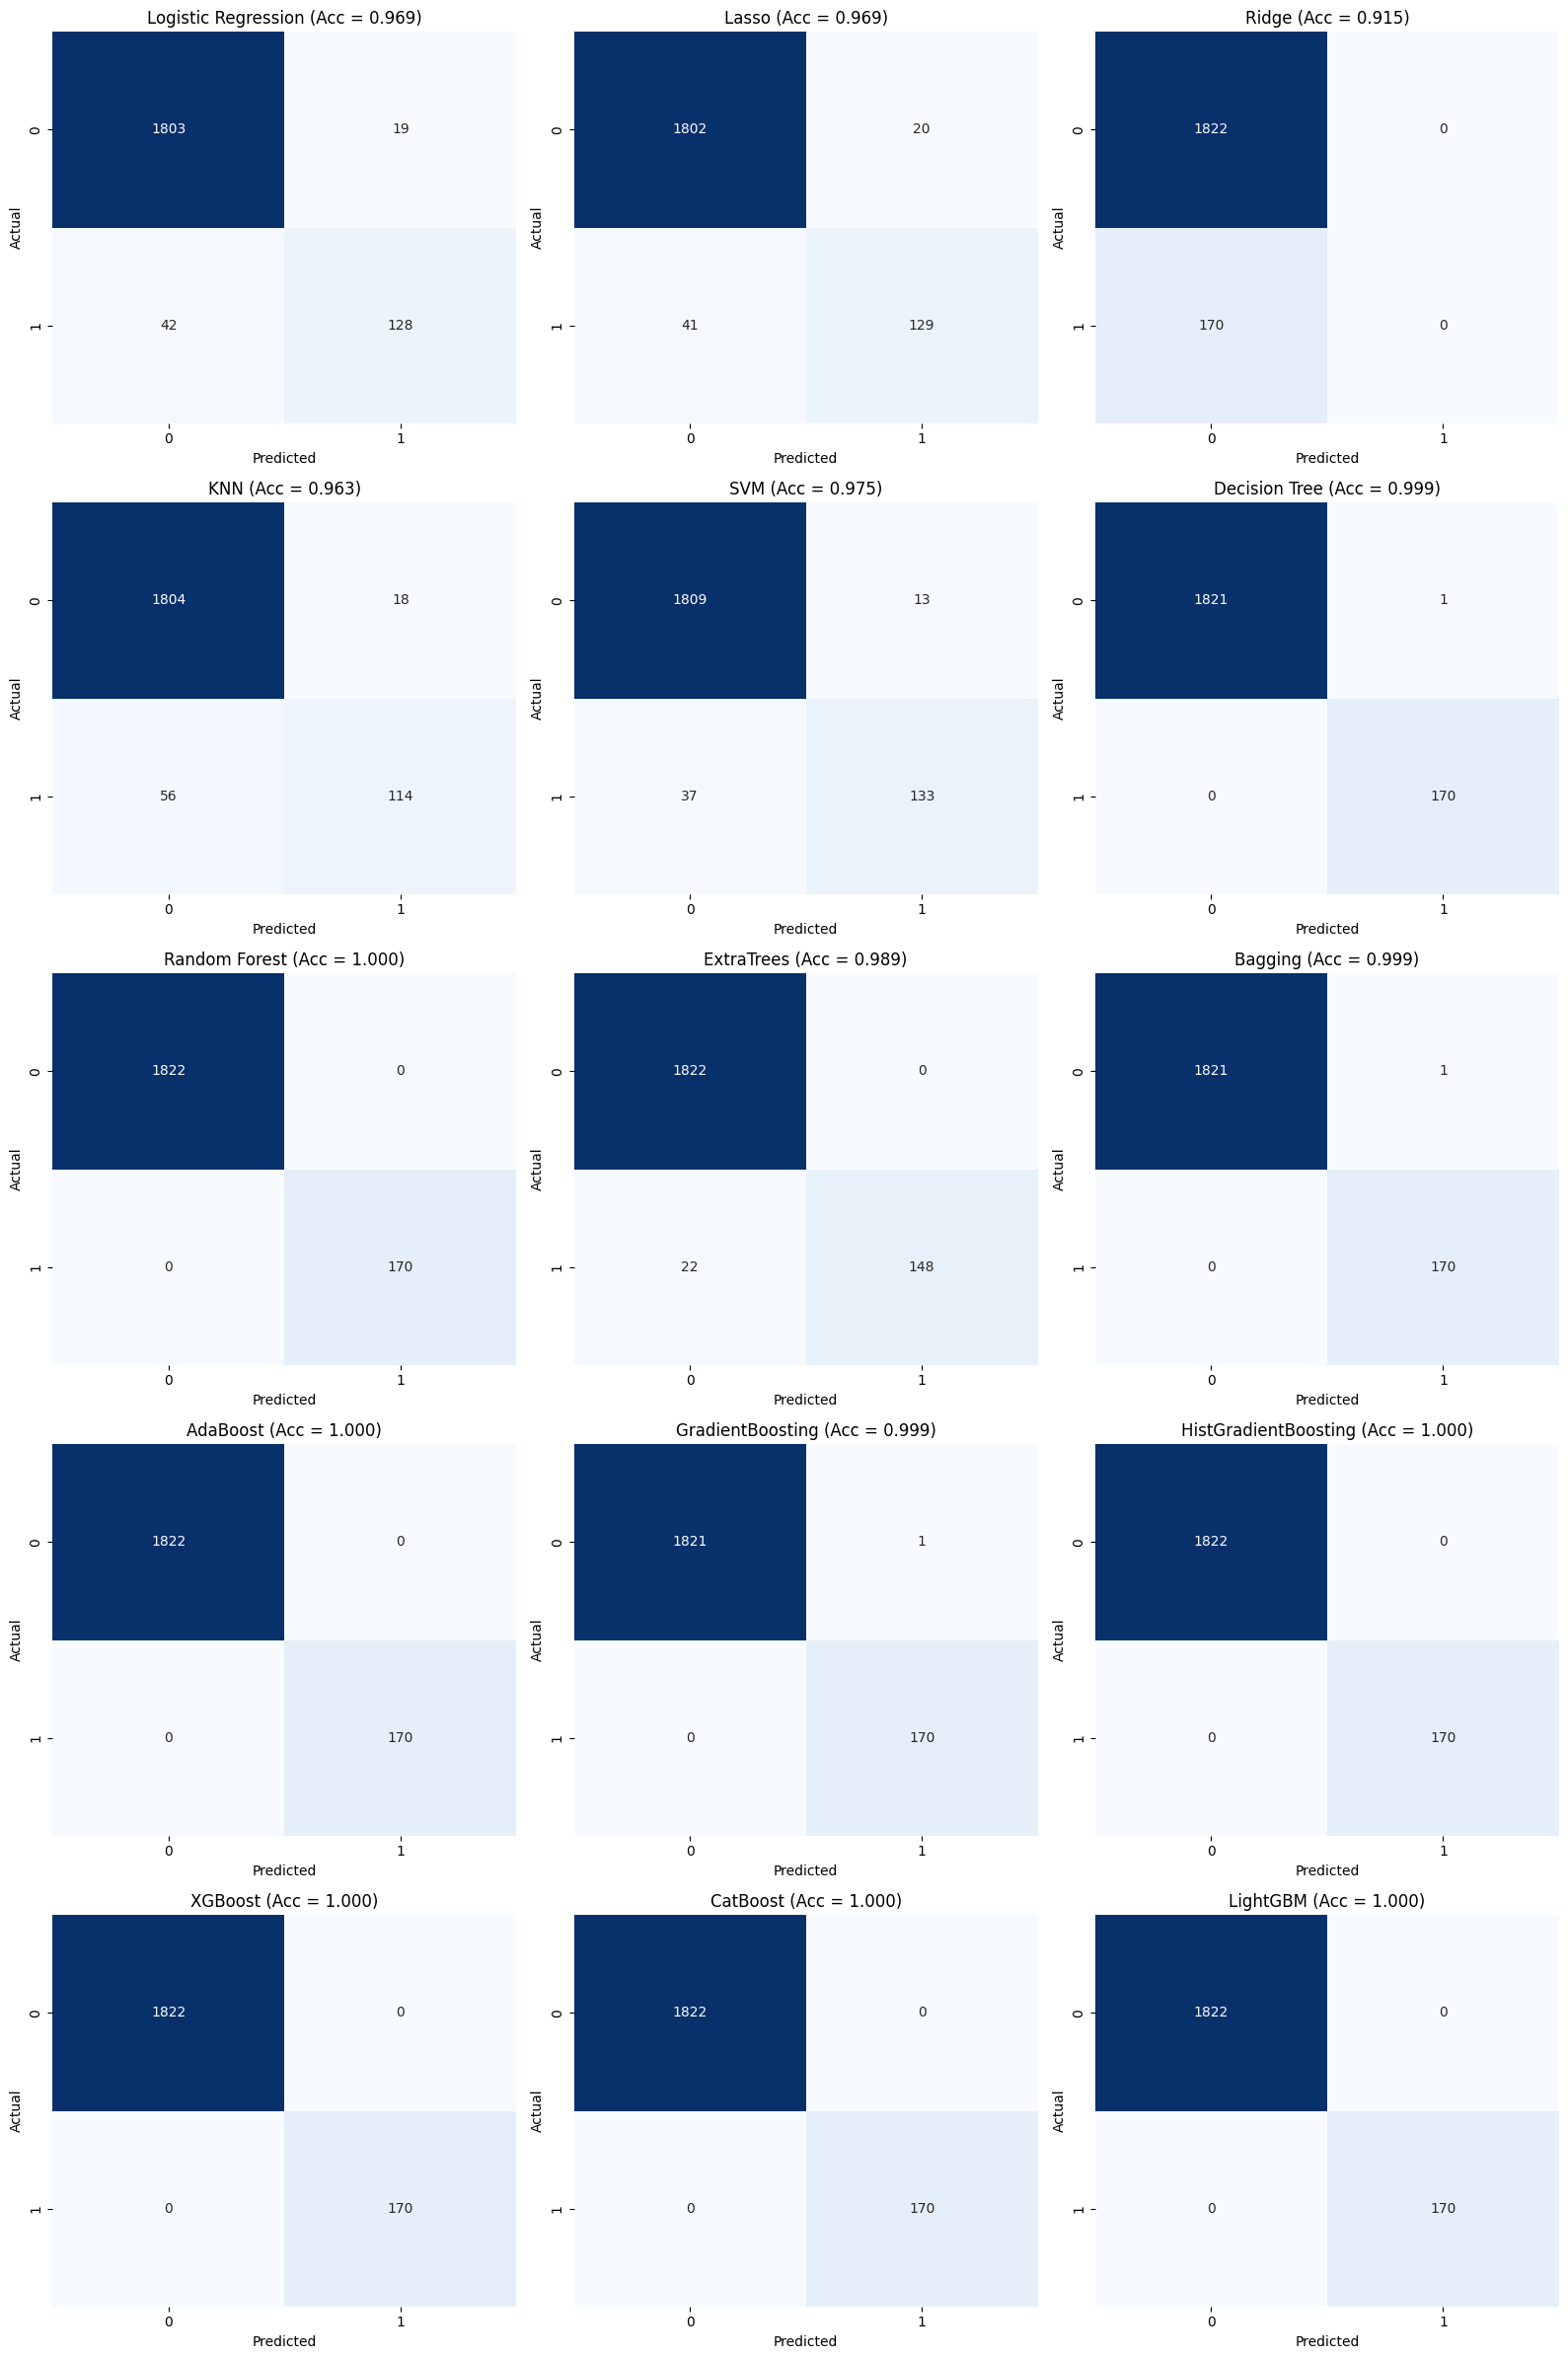

In [34]:
fig, axes = plt.subplots(5, 3, figsize=(16, 24))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(clf_preds.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i])
    axes[i].set_title(f"{name} (Acc = {accuracy_score(y_test, y_pred):.3f})")
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Model comparison (F1)

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(data=clf_results_df, x='F1 Score', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('F1 Score Comparison')
plt.show()

## Select the best model
We pick the best model using Cross Validation on the training set only (the test set is not touched).

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score

cv_scores = {}
for name, m in clf_models.items():
    cv_scores[name] = cross_val_score(clone(m), X_train_scaled, y_train, cv=3, scoring='f1', n_jobs=-1).mean()

cv_df = pd.DataFrame({'Model': list(cv_scores.keys()), 'CV F1': list(cv_scores.values())})
cv_df = cv_df.sort_values(by='CV F1', ascending=False).reset_index(drop=True)
cv_df

## GridSearchCV on the best model

In [ ]:
param_grids = {
    "Logistic Regression": {"C": [0.1, 1, 10]},
    "Lasso": {"C": [0.1, 1, 10]},
    "Ridge": {"alpha": [0.1, 1, 10]},
    "KNN": {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]},
    "SVM": {"C": [0.1, 1, 10]},
    "Decision Tree": {"max_depth": [5, 10, 15, None], "min_samples_split": [2, 10]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "ExtraTrees": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "Bagging": {"n_estimators": [15, 30, 50]},
    "AdaBoost": {"n_estimators": [50, 100], "learning_rate": [0.1, 1]},
    "GradientBoosting": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
    "HistGradientBoosting": {"max_iter": [100, 200], "learning_rate": [0.05, 0.1]},
    "XGBoost": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 6]},
    "CatBoost": {"iterations": [100, 300], "depth": [4, 6]},
    "LightGBM": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "num_leaves": [31, 63]},
}

best_name = cv_df.loc[0, 'Model']
print('Best model:', best_name)

grid = GridSearchCV(clone(clf_models[best_name]), param_grids.get(best_name, {}), cv=3, scoring='f1', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('best_params_:', grid.best_params_)
print('best_score_ :', grid.best_score_)

best_model = grid.best_estimator_

## Before vs after tuning (test set)

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

base_model = clone(clf_models[best_name])
base_model.fit(X_train_scaled, y_train)

rows = []
for label, m in [('Before tuning', base_model), ('After tuning', best_model)]:
    p = m.predict(X_test_scaled)
    rows.append({'Version': label,
                 'Accuracy': accuracy_score(y_test, p),
                 'Precision': precision_score(y_test, p, zero_division=0),
                 'Recall': recall_score(y_test, p, zero_division=0),
                 'F1': f1_score(y_test, p, zero_division=0)})
pd.DataFrame(rows)

## Final evaluation

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

y_pred = best_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_estimator(best_model, X_test_scaled, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], color='red', linestyle='--')
axes[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_estimator(best_model, X_test_scaled, y_test, ax=axes[2])
axes[2].set_title('Precision-Recall Curve')

plt.tight_layout()
plt.show()

### Interpretation (generated automatically)

In [ ]:
# Plain-English summary, generated from the real results above
from sklearn.metrics import confusion_matrix

if hasattr(best_model, 'predict_proba'):
    scores = best_model.predict_proba(X_test_scaled)[:, 1]
else:
    scores = best_model.decision_function(X_test_scaled)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Best model: {best_name} with {grid.best_params_}")
print(f"- Accuracy = {acc:.3f}: {acc*100:.1f}% of all predictions are correct.")
print(f"- Precision = {prec:.3f}: when the model predicts the positive class, it is right {prec*100:.1f}% of the time ({fp} false alarms).")
print(f"- Recall = {rec:.3f}: the model finds {rec*100:.1f}% of the real positive cases and misses {fn}.")
print(f"- F1 = {f1:.3f}: the balance between precision and recall.")
print(f"- ROC-AUC = {roc_auc_score(y_test, scores):.3f}: the chance that a random positive case is ranked above a random negative one.")
print(f"- Average Precision (PR curve) = {average_precision_score(y_test, scores):.3f}: more reliable than accuracy when the classes are imbalanced.")
if rec < prec:
    print("- Recall is lower than precision: the model is careful but misses some positive cases.")
else:
    print("- Precision is lower than recall: the model catches most positive cases but raises some false alarms.")